In [ ]:
import cv2
import numpy as np
import requests
from google.colab.patches import cv2_imshow
from IPython.display import display

In [ ]:
# Direct image URL
url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg"

In [ ]:
# Download the image
response = requests.get(url, timeout=30)
response.raise_for_status()

In [ ]:
# Convert image bytes into a NumPy array
image_array = np.frombuffer(response.content, dtype=np.uint8)

Image loaded successfully!


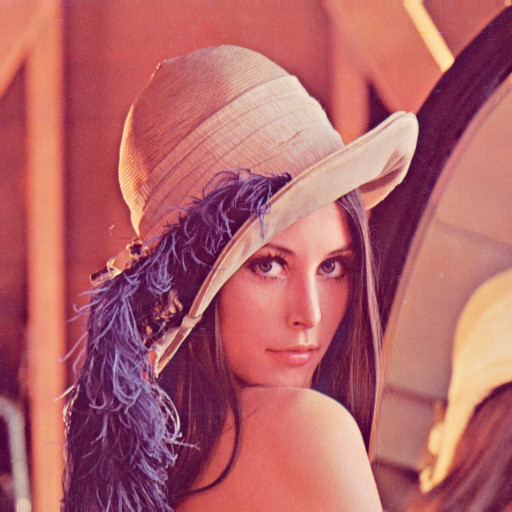

In [ ]:
# Decode the image using OpenCV
img = cv2.imdecode(image_array, cv2.IMREAD_COLOR)

# Check whether the image was loaded successfully
if img is not None:
    print("Image loaded successfully!")
    cv2_imshow(img)
else:
    print("Unable to decode the image.")

In [ ]:
img.size

786432

In [ ]:
img.shape

(512, 512, 3)

In [ ]:
import matplotlib.pyplot as plt

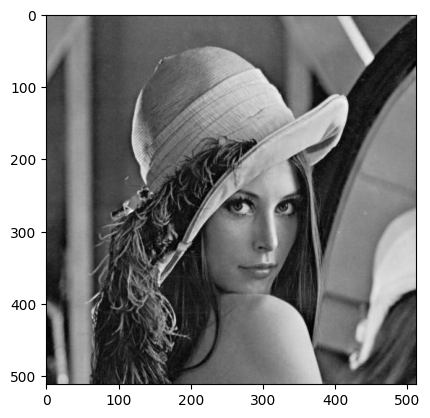

In [ ]:
b,g,r=cv2.split(img)
plt.imshow(g, cmap='gray')

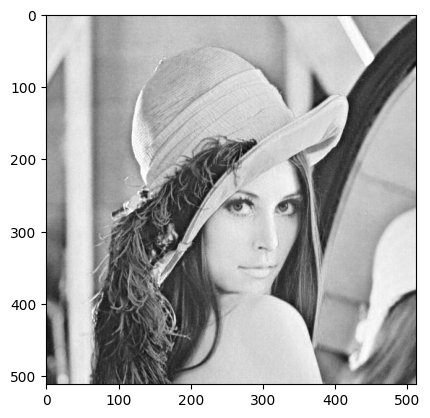

In [ ]:
plt.imshow(r, cmap='gray')

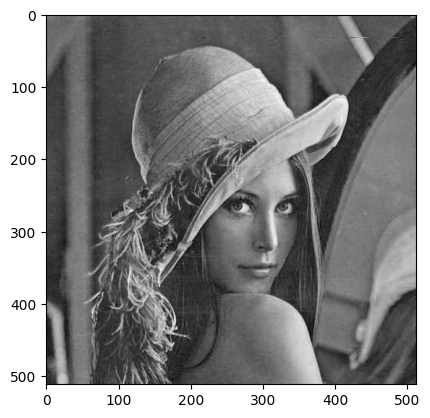

In [ ]:
plt.imshow(b, cmap='gray')

# Channels

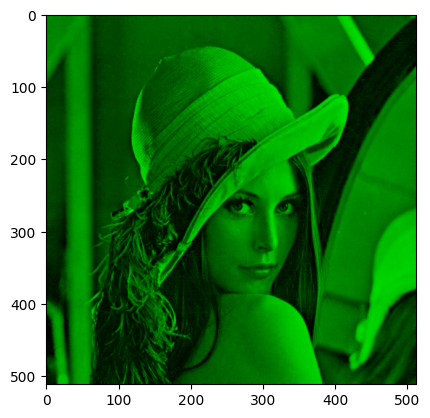

In [ ]:
g = img.copy()

# set blue and red channels to 0
g[:, :, 0] = 0     # 0 means channel red
g[:, :, 2] = 0     # 2 means channel blue ,  1 is green channel
plt.imshow(g)

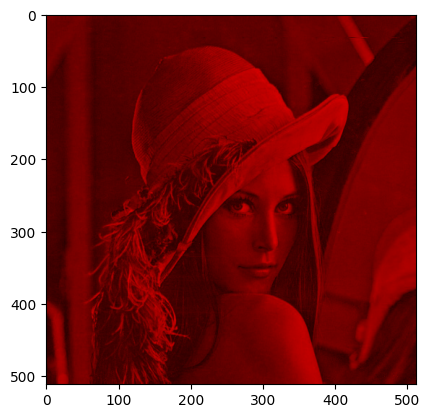

In [ ]:
r = img.copy()

# set blue and green channels to 0
r[:, :, 1] = 0     # 1 means channel green
r[:, :, 2] = 0     # 2 means channel blue
plt.imshow(r)

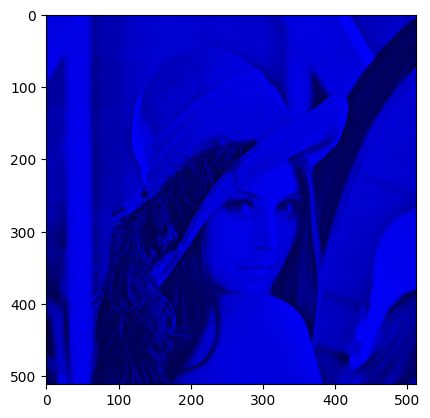

In [ ]:
b  = img.copy()


b[:, :, 0] = 0
b[:, :, 1] = 0
plt.imshow(b)

# Blurring

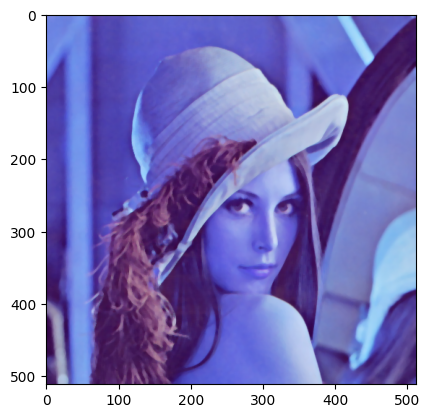

In [ ]:
medBlur = cv2.medianBlur(img, 5)         # 5 is the filter size
plt.imshow(medBlur)

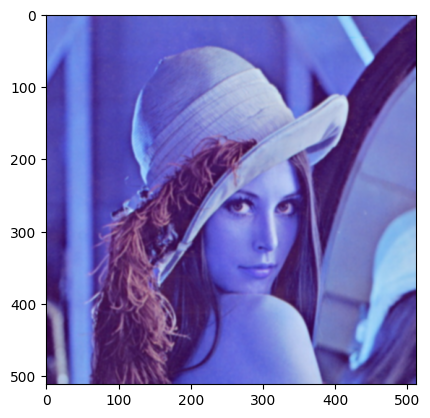

In [ ]:
gausBlur = cv2.GaussianBlur(img, (5,5),0)         # (5,5) is the filter size
plt.imshow(gausBlur)

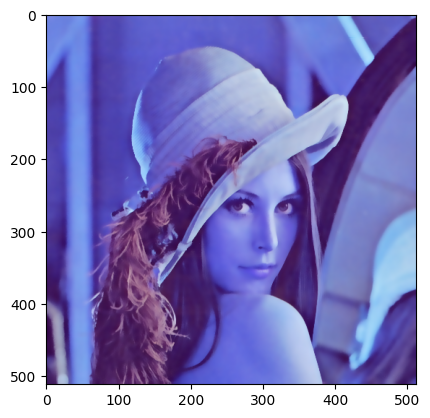

In [ ]:
bilateral = cv2.bilateralFilter(img, 9, 75, 75)
plt.imshow(bilateral)

# Histogram Equalization

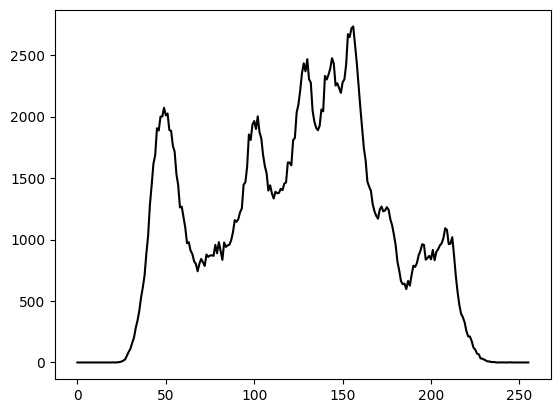

In [ ]:
gray_image = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
histogram = cv2.calcHist([gray_image], [0], None, [256], [0, 256])
plt.plot(histogram, color='k')
plt.show()

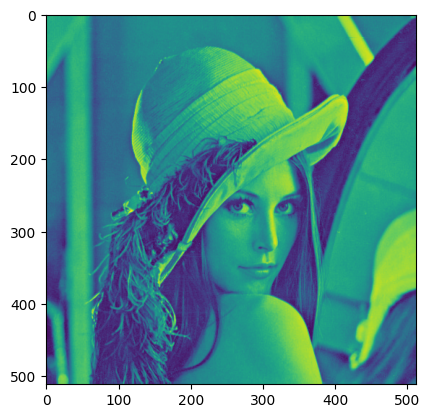

In [ ]:
image1 = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
cv2.equalizeHist(image1)
plt.imshow(image1)

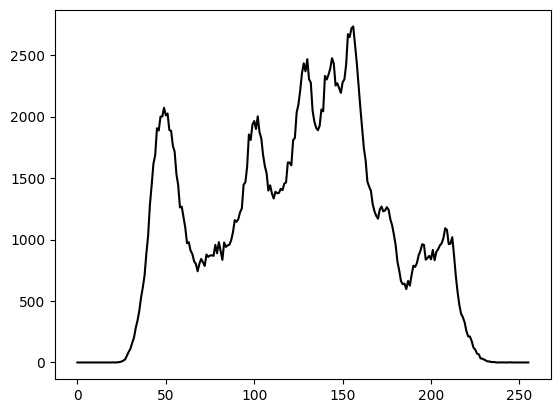

In [ ]:
histogram = cv2.calcHist([image1], [0], None, [256], [0, 256])
plt.plot(histogram, color='k')
plt.show()

# Augumentations

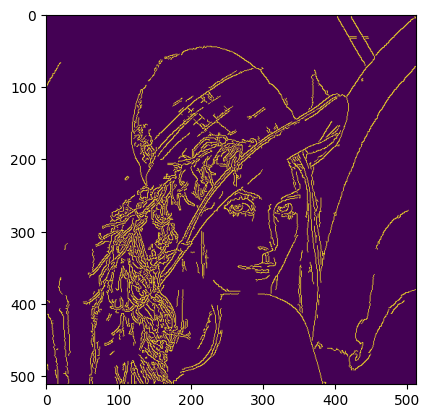

In [ ]:
edges = cv2.Canny(img, threshold1=100, threshold2=200)
plt.imshow(edges)

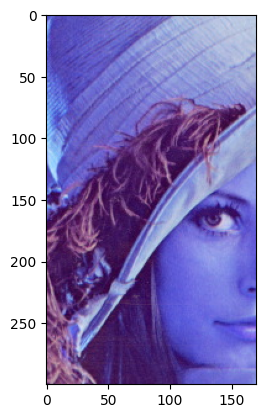

In [ ]:
crop = img[100:400, 130:300]   # [row indices, column indices]
plt.imshow(crop)

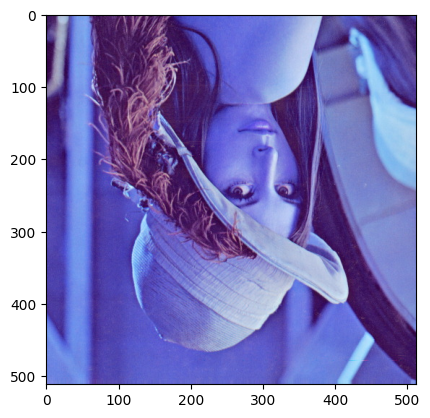

In [ ]:
image2 = cv2.flip(img, 0)
plt.imshow(image2)

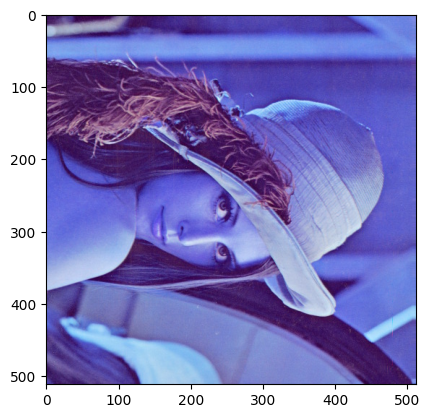

In [ ]:
img_rotate_90_clockwise = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)
plt.imshow(img_rotate_90_clockwise)

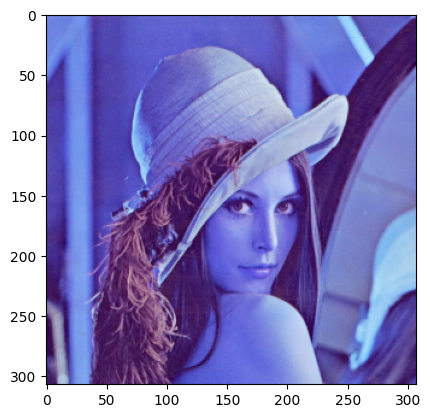

In [ ]:
scale_percent = 60 # percent of original size
width = int(img.shape[1] * scale_percent / 100)
height = int(img.shape[0] * scale_percent / 100)
dim = (width, height)

# resize image
resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
plt.imshow(resized)